<a href="https://colab.research.google.com/github/juanarrow/BigData-notebooks/blob/main/matplotlib.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tipos de gráfico (Chart Chooser)

Un ejemplo de cada tipo de gráfico del *Chart Chooser* de Andrew V. Abela (2020), agrupados por lo que quiere mostrar el gráfico: **comparación**, **relación**, **distribución** y **composición**.

El gráfico de dispersión aparece en el PDF en dos ramas (relación y distribución); se muestra una sola vez en la sección de relación.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import LinearSegmentedColormap, to_rgb

# Paleta categórica (modo claro) y colores de texto/superficie
SURFACE = "#fcfcfb"
TEXT, TEXT2, GRID = "#0b0b0b", "#52514e", "#e3e2de"
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT2, "xtick.color": TEXT2, "ytick.color": TEXT2,
    "text.color": TEXT, "axes.titlelocation": "left", "axes.titleweight": "semibold",
    "axes.titlesize": 12, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 1,
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "legend.frameon": False,
    "font.size": 10, "figure.dpi": 110,
})

rng = np.random.default_rng(7)
MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
TRIM = ["T1", "T2", "T3", "T4"]
AREAS = ["Ventas", "Marketing", "Soporte", "I+D"]


def xgrid(ax):
    ax.grid(False)
    ax.grid(True, axis="x")

def ygrid(ax):
    # Rejilla solo horizontal, discreta
    ax.grid(False)
    ax.grid(True, axis="y")

def fmt_mes(m):
    return f"{MESES[m % 12]} {2023 + m // 12}"

## Comparación

### Estática (una foto, sin tiempo)

**Single Bar Chart** — compara el valor de una sola variable entre varias categorías.

- **Cuándo usarlo:** para comparar magnitudes entre categorías (ventas por área, gasto por departamento).
- **Cómo leerlo:** la longitud de cada barra es el valor; ordenarlas de mayor a menor facilita el ranking.
- **Evitar:** que el eje no empiece en cero, porque exagera las diferencias.

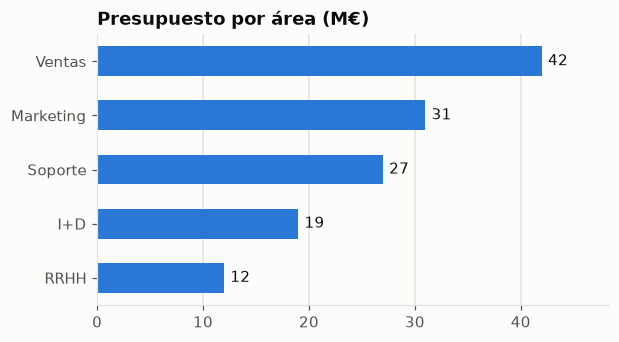

In [ ]:
cats = ["Ventas", "Marketing", "Soporte", "I+D", "RRHH"]
vals = [42, 31, 27, 19, 12]

fig, ax = plt.subplots(figsize=(6, 3.2))
bars = ax.barh(cats, vals, color=PAL[0], height=0.55)
ax.invert_yaxis()    # el primero arriba
ax.bar_label(bars, padding=4, color=TEXT)
ax.set_xlim(0, max(vals) * 1.15)
ax.grid(False)
ax.grid(True, axis="x")
ax.set_title("Presupuesto por área (M€)")
plt.show()

**Variable Width Column Chart** — muestra dos variables a la vez: la altura de cada columna es un valor (ventas) y su ancho es otra magnitud (cuota de mercado).

- **Cuándo usarlo:** cuando interesa tanto el tamaño de cada categoría como su peso relativo en el total.
- **Cómo leerlo:** el área de cada columna (ancho × alto) representa el total de esa categoría; una columna ancha y alta pesa más.
- **Evitar:** comparar solo alturas si el ancho cambia mucho, porque el ojo se fija en el área.

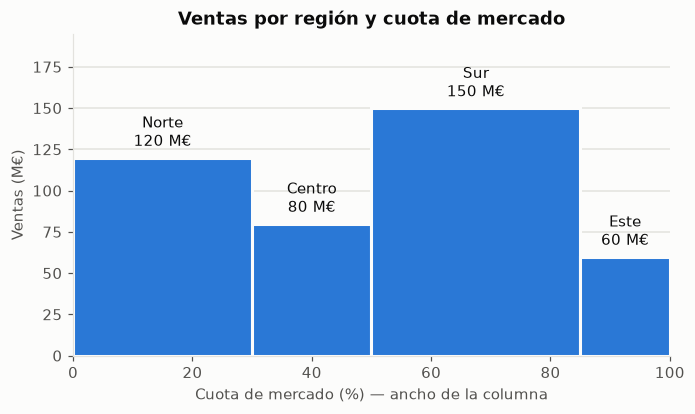

In [ ]:
regiones = ["Norte", "Centro", "Sur", "Este"]
ventas = np.array([120, 80, 150, 60])
cuota = np.array([30, 20, 35, 15])
# ancho de cada columna (suma 100)
x0 = np.concatenate([[0], np.cumsum(cuota)[:-1]])  # borde izquierdo de cada columna

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(x0, ventas, width=cuota, align="edge", color=PAL[0], edgecolor=SURFACE, linewidth=2)
for x, w, h, r in zip(x0, cuota, ventas, regiones):
    ax.text(x + w / 2, h + 4, f"{r}\n{h} M€", ha="center", va="bottom", color=TEXT)
ax.set_xlim(0, cuota.sum())
ax.set_ylim(0, ventas.max() * 1.3)
ax.set_xlabel("Cuota de mercado (%) — ancho de la columna")
ax.set_ylabel("Ventas (M€)")
ygrid(ax)
ax.set_title("Ventas por región y cuota de mercado", loc="center")
plt.show()

**Multiple Bar Charts** — pocos ítems con tres o más variables: barras agrupadas, una barra por año dentro de cada área.

- **Cuándo usarlo:** para comparar varias series entre pocas categorías (presupuesto de tres años en tres áreas).
- **Cómo leerlo:** compara primero dentro de cada grupo (mismo color, distintos años) y después entre grupos.
- **Evitar:** demasiadas series por grupo; con más de tres o cuatro barras por categoría se vuelve difícil de leer.

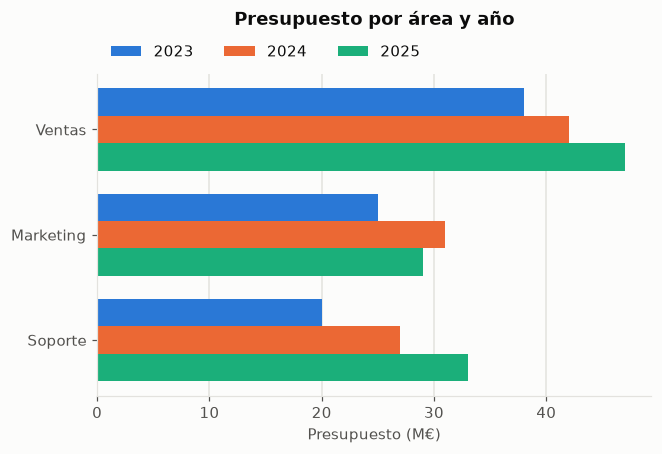

In [ ]:
areas = ["Ventas", "Marketing", "Soporte"]
anios = {"2023": [38, 25, 20], "2024": [42, 31, 27], "2025": [47, 29, 33]}

y = np.arange(len(areas))
h = 0.26
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for i, (anio, v) in enumerate(anios.items()):
    ax.barh(y + (i - 1) * h, v, height=h, color=PAL[i], label=anio)
ax.set_yticks(y, areas)
ax.invert_yaxis()
ax.set_xlabel("Presupuesto (M€)")
xgrid(ax)
ax.legend(ncols=3, loc="lower left", bbox_to_anchor=(0, 1.0))
ax.set_title("Presupuesto por área y año", loc="center", pad=32)
plt.show()

**Table with Embedded Charts** — muchos ítems con tres o más variables: una tabla en la que cada fila incluye su propio mini-gráfico.

- **Cuándo usarlo:** cuando hay muchos elementos y cada uno necesita su evolución, pero un gráfico único se saturaría.
- **Cómo leerlo:** cada fila es un elemento; el mini-gráfico muestra su tendencia y la última columna su total.
- **Evitar:** mini-gráficos sin escala común; aquí todos comparten el mismo rango (0–100), así que son comparables entre filas.

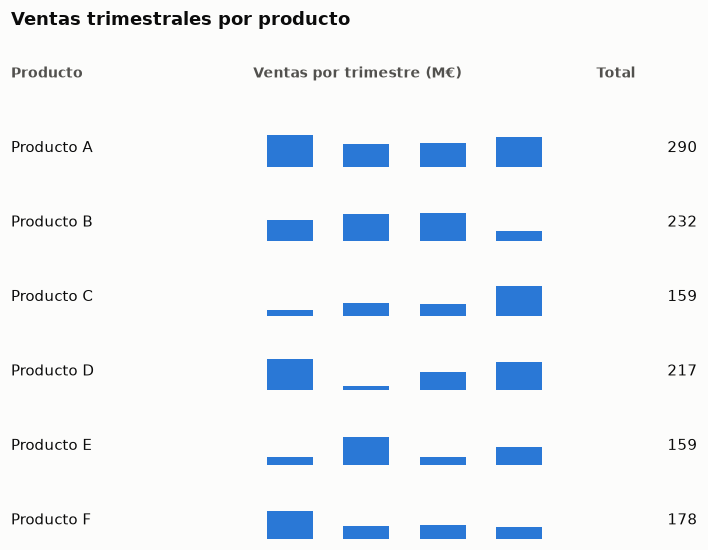

In [ ]:
productos = [f"Producto {c}" for c in "ABCDEF"]
trim_vals = rng.integers(10, 90, size=(len(productos), 4))

fig, axes = plt.subplots(len(productos) + 1, 3, figsize=(6.5, 5),
                         gridspec_kw={"width_ratios": [2, 3, 1]})
fig.subplots_adjust(hspace=1, left=0.02, right=0.98, top=0.9, bottom=0.02)

# Cabecera
for ax, titulo in zip(axes[0], ["Producto", "Ventas por trimestre (M€)", "Total"]):
    ax.text(0, 0.5, titulo, transform=ax.transAxes, va="center", color=TEXT2, fontsize=9, fontweight="semibold")

# Filas: nombre | mini-columnas | total
for i, (nombre, q) in enumerate(zip(productos, trim_vals), start=1):
    ax_name, ax_bar, ax_tot = axes[i]
    ax_name.text(0, 0.5, nombre, transform=ax_name.transAxes, va="center")
    ax_bar.bar(range(4), q, width=0.6, color=PAL[0])
    ax_bar.set_ylim(0, 100)
    ax_tot.text(1, 0.5, f"{q.sum()}", transform=ax_tot.transAxes, va="center", ha="right")

for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Ventas trimestrales por producto", x=0.02, ha="left", fontsize=12, fontweight="semibold")
plt.show()

### Cambio en el tiempo

**Circular Area Chart** — datos cíclicos (los meses forman un ciclo) dibujados en coordenadas polares; cada eje es un mes y la distancia al centro es el valor.

- **Cuándo usarlo:** para patrones que se repiten, como estaciones, horas del día o días de la semana.
- **Cómo leerlo:** la forma muestra el ciclo; comparar dos polígonos permite ver si un año es más alto o más bajo en cada mes.
- **Evitar:** datos sin ciclo real, porque el cierre circular sugiere que diciembre y enero están conectados. Es más difícil de leer valores exactos que en una línea.

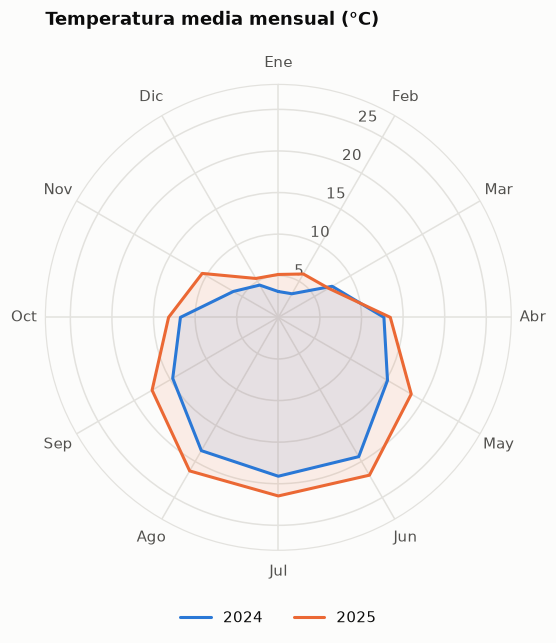

In [ ]:
theta = np.linspace(0, 2 * np.pi, 12, endpoint=False)
theta_c = np.append(theta, theta[0])

estacional = 12 + 9 * np.sin(theta - np.pi / 2)   # pico hacia julio
series = {
    "2024": estacional + rng.normal(0, 1, 12),
    "2025": estacional + 2 + rng.normal(0, 1, 12),
}

fig = plt.figure(figsize=(5.5, 5.5))
ax = fig.add_subplot(projection="polar")
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.set_xticks(theta, MESES)
ax.set_ylim(0, 28)
for i, (anio, v) in enumerate(series.items()):
    v_c = np.append(v, v[0])
    ax.plot(theta_c, v_c, color=PAL[i], label=anio)
    ax.fill(theta_c, v_c, color=PAL[i], alpha=0.1)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=2)
ax.set_title("Temperatura media mensual (°C)", pad=20)
plt.show()

**Line Chart (datos no cíclicos, muchos periodos)** — una serie de valores a lo largo de muchos periodos (36 meses).

- **Cuándo usarlo:** para ver tendencias y cambios de dirección en el tiempo.
- **Cómo leerlo:** la pendiente indica la velocidad del cambio; los picos y valles marcan los momentos clave. Aquí se etiqueta el último valor.
- **Evitar:** cortar el eje vertical lejos de cero si la intención es comparar magnitudes; para tendencias sí es aceptable.

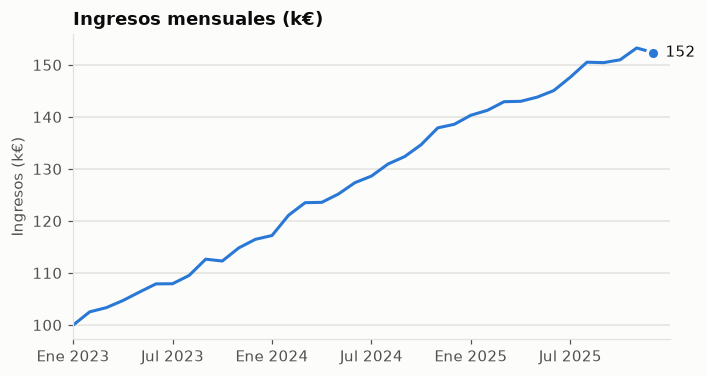

In [ ]:
periodos = np.arange(36)
ingresos = 100 + 1.5 * periodos + np.cumsum(rng.normal(0, 1.2, 36))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(periodos, ingresos, color=PAL[0])
ax.plot(periodos[-1], ingresos[-1], "o", color=PAL[0], markersize=8,
        markeredgecolor=SURFACE, markeredgewidth=2)
ax.annotate(f"{ingresos[-1]:.0f}", (periodos[-1], ingresos[-1]),
            xytext=(8, 0), textcoords="offset points", va="center", color=TEXT)
ax.set_xticks(periodos[::6], [fmt_mes(m) for m in periodos[::6]])
ax.set_xlim(0, 36)
ax.set_ylabel("Ingresos (k€)")
ygrid(ax)
ax.set_title("Ingresos mensuales (k€)")
plt.show()

**Column Chart (pocos ítems, pocos periodos)** — columnas agrupadas verticalmente: dos productos en cuatro trimestres.

- **Cuándo usarlo:** para comparar pocos elementos en pocos periodos, con un vistazo rápido.
- **Cómo leerlo:** compara la altura de columnas del mismo color para ver la evolución de cada producto y, dentro del mismo trimestre, cuál vende más.
- **Evitar:** muchos periodos (se vuelve estrecho e ilegible); en ese caso usa una línea.

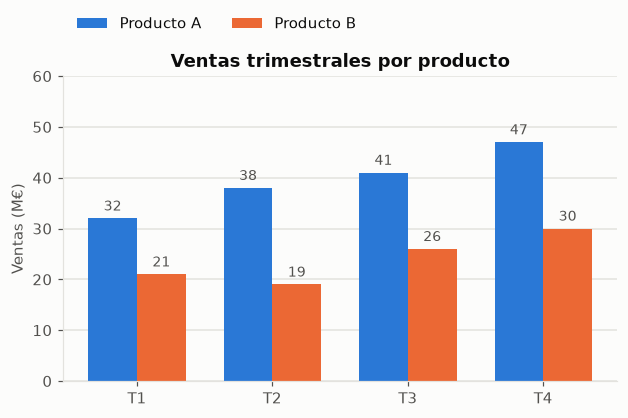

In [ ]:
ventas = {"Producto A": [32, 38, 41, 47], "Producto B": [21, 19, 26, 30]}

x = np.arange(len(TRIM))
w = 0.36
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for i, (nombre, v) in enumerate(ventas.items()):
    b = ax.bar(x + (i - 0.5) * w, v, width=w, color=PAL[i], label=nombre)
    ax.bar_label(b, padding=3, fontsize=9, color=TEXT2)
ax.set_xticks(x, TRIM)
ax.set_ylim(0, 60)
ax.set_ylabel("Ventas (M€)")
ygrid(ax)
ax.legend(ncols=2, loc="lower left", bbox_to_anchor=(0, 1.1))
ax.set_title("Ventas trimestrales por producto", loc="center")
plt.show()

**Line Chart (muchos ítems, pocos periodos)** — varias series de líneas a lo largo de pocos años (seis productos, cinco años).

- **Cuándo usarlo:** para comparar la evolución de muchos elementos a la vez.
- **Cómo leerlo:** cada color es un producto; interesa ver cuáles suben, cuáles bajan y cuáles se cruzan.
- **Evitar:** demasiadas líneas: con muchas series, se usa leyenda en lugar de etiquetas directas, y si se cruzan mucho conviene dividir el gráfico en varios pequeños.

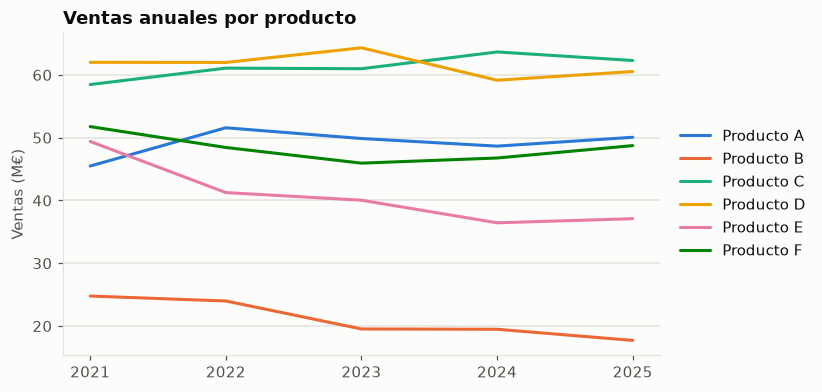

In [ ]:
anios = ["2021", "2022", "2023", "2024", "2025"]
productos = [f"Producto {c}" for c in "ABCDEF"]
base = rng.uniform(20, 60, len(productos))
ventas = base[:, None] + rng.normal(0, 4, (len(productos), 5)).cumsum(axis=1)

fig, ax = plt.subplots(figsize=(7, 3.8))
for i, (nombre, v) in enumerate(zip(productos, ventas)):
    ax.plot(anios, v, color=PAL[i], label=nombre)
ax.set_ylabel("Ventas (M€)")
ygrid(ax)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
ax.set_title("Ventas anuales por producto")
plt.show()

## Relación

**Scatter Chart** — dos variables numéricas: cada punto es un caso (una persona, en este ejemplo) con sus horas de estudio y su nota.

- **Cuándo usarlo:** para ver si dos variables están relacionadas (correlación) y detectar valores atípicos.
- **Cómo leerlo:** si los puntos forman una nube inclinada hacia arriba, hay relación positiva; si están dispersos sin forma, casi no hay relación.
- **Evitar:** interpretar causalidad solo por la correlación; aquí más horas tienden a dar más nota, pero el gráfico no prueba que una cause la otra.

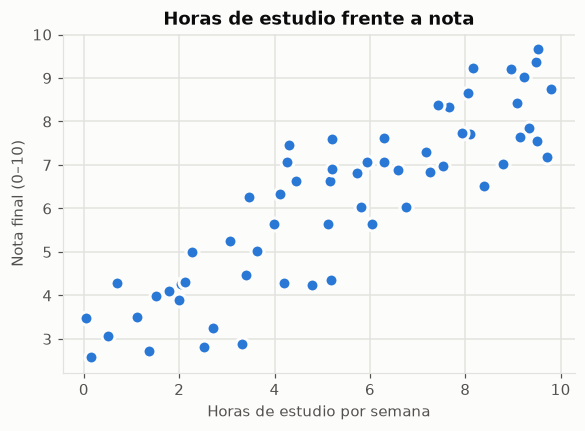

In [ ]:
horas = rng.uniform(0, 10, 60)
nota = 3 + 0.6 * horas + rng.normal(0, 1, 60)

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(horas, nota, s=72, color=PAL[0], edgecolor=SURFACE, linewidth=2)  # anillo de superficie
ax.set_xlabel("Horas de estudio por semana")
ax.set_ylabel("Nota final (0–10)")
ax.set_title("Horas de estudio frente a nota", loc="center")
plt.show()

**Bubble Chart** — tres variables: la posición en x e y (precio y satisfacción) y el tamaño de cada burbuja (ventas).

- **Cuándo usarlo:** cuando un gráfico de dispersión necesita una tercera magnitud.
- **Cómo leerlo:** las burbujas grandes son las de más ventas; la posición indica precio y satisfacción. Usa la leyenda de tamaños para estimar el valor.
- **Evitar:** burbujas casi del mismo tamaño o demasiadas burbujas solapadas; el área se percibe peor que la longitud, así que las diferencias pequeñas son difíciles de ver.

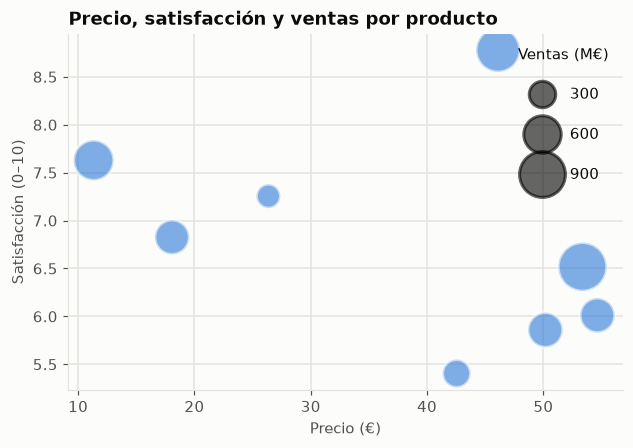

In [ ]:
n = 8
precio = rng.uniform(10, 60, n)
satisf = rng.uniform(5, 9, n)
ventas = rng.uniform(5, 60, n)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
sc = ax.scatter(precio, satisf, s=ventas * 20, color=PAL[0], alpha=0.6,
                edgecolor=SURFACE, linewidth=2)
handles, labels = sc.legend_elements(prop="sizes", num=3, alpha=0.6)
ax.legend(handles, labels, title="Ventas (M€)", loc="upper right", labelspacing=1.6)
ax.set_xlabel("Precio (€)")
ax.set_ylabel("Satisfacción (0–10)")
ax.set_title("Precio, satisfacción y ventas por producto")
plt.show()

## Distribución

**Column Histogram** — una variable numérica: cuenta cuántos casos caen en cada intervalo (bin) de valores.

- **Cuándo usarlo:** para ver la forma de una distribución: dónde se concentran los datos, si es simétrica o tiene colas.
- **Cómo leerlo:** la altura de cada columna es el número de clientes en ese rango de edad; aquí la mayoría tienen entre 27 y 49 años, con el pico alrededor de los 38.
- **Evitar:** cambiar el número de intervalos sin revisar; demasiados producen ruido y pocos ocultan la forma.

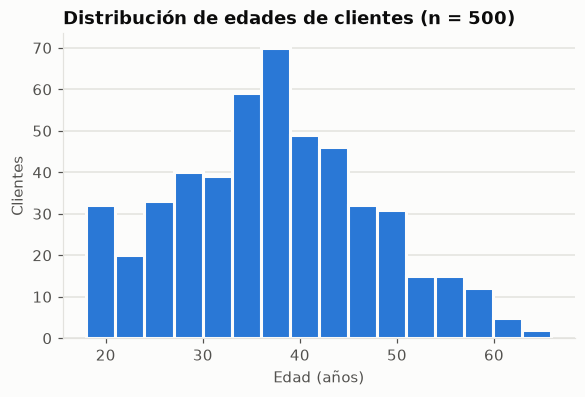

In [ ]:
edades = rng.normal(38, 11, 500).clip(18, 80)

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.hist(edades, bins=16, color=PAL[0], edgecolor=SURFACE, linewidth=2)
ax.set_xlabel("Edad (años)")
ax.set_ylabel("Clientes")
ygrid(ax)
ax.set_title("Distribución de edades de clientes (n = 500)")
plt.show()

**Line Histogram** — la misma distribución que el histograma anterior, pero dibujada como curva suavizada (estimación de densidad por núcleos gaussianos).

- **Cuándo usarlo:** para comparar distribuciones entre sí, porque varias curvas se superponen mejor que varios histogramas de columnas.
- **Cómo leerlo:** el pico marca el valor más frecuente; el área bajo la curva suma 1, así que el eje vertical es densidad, no un recuento.
- **Evitar:** un ancho de suavizado muy grande, que borra detalles, o muy pequeño, que dibuja picos falsos.

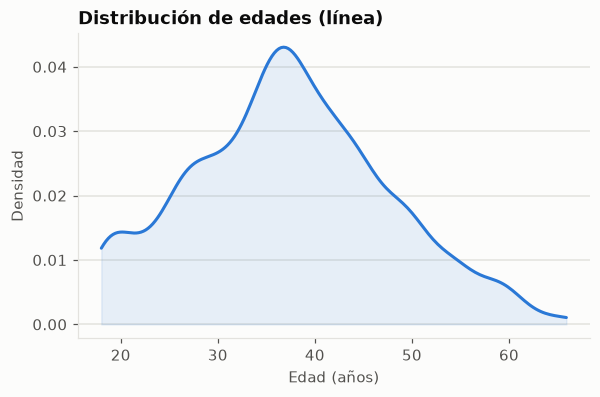

In [ ]:
xs = np.linspace(edades.min(), edades.max(), 200)
ancho = 2.0                                     # ancho de banda del suavizado
dens = np.exp(-0.5 * ((xs[:, None] - edades[None, :]) / ancho) ** 2).sum(axis=1)
dens /= len(edades) * ancho * np.sqrt(2 * np.pi)

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(xs, dens, color=PAL[0])
ax.fill_between(xs, dens, color=PAL[0], alpha=0.1)
ax.set_xlabel("Edad (años)")
ax.set_ylabel("Densidad")
ygrid(ax)
ax.set_title("Distribución de edades (línea)")
plt.show()

**3D Area Chart** — tres variables: mes (x), producto (y) y ventas (z), dibujadas como superficie.

- **Cuándo usarlo:** para mostrar una cuadrícula de valores cuando el patrón general importa más que los valores exactos.
- **Cómo leerlo:** las crestas son meses o productos con más ventas; la perspectiva hace difícil comparar alturas precisas.
- **Evitar:** casi siempre. Las superficies 3D ocultan valores detrás de otros y dificultan la lectura; si puedes, usa un mapa de calor o líneas por producto.

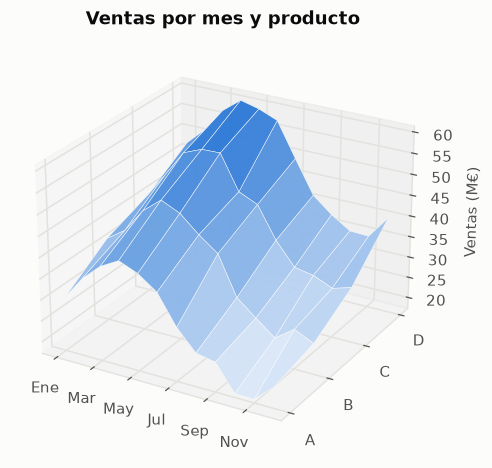

In [ ]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (activa la proyección 3D)

meses_x = np.arange(12)
prod_y = np.arange(4)
X, Y = np.meshgrid(meses_x, prod_y)
Z = 30 + 12 * np.sin(X / 2) + 6 * Y + rng.normal(0, 1.5, X.shape)

cmap = LinearSegmentedColormap.from_list("azul", ["#dbe8f9", PAL[0]])  # una sola tonalidad
fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X, Y, Z, cmap=cmap, edgecolor=SURFACE, linewidth=0.3, alpha=0.95)
ax.set_xticks(meses_x[::2], [MESES[i] for i in meses_x[::2]])
ax.set_yticks(prod_y, ["A", "B", "C", "D"])
ax.set_zlabel("Ventas (M€)")
ax.view_init(elev=25, azim=-60)
ax.set_title("Ventas por mes y producto")
plt.show()

## Composición

### Cambio en el tiempo, pocos periodos

Los cuatro gráficos siguientes usan los mismos datos: cuatro trimestres y cuatro áreas.

In [ ]:
datos = rng.integers(10, 60, size=(4, 4)).astype(float)   # filas = trimestres, columnas = áreas
pct = datos / datos.sum(axis=1, keepdims=True) * 100       # cada columna suma 100 %

**Stacked 100% Column Chart** — pocos periodos; cada columna suma el 100 % y lo que importa es el reparto relativo.

- **Cuándo usarlo:** para comparar cómo cambia la proporción de cada parte a lo largo de unos pocos periodos.
- **Cómo leerlo:** la altura de cada segmento es su porcentaje dentro de ese trimestre; los segmentos no muestran el volumen total.
- **Evitar:** querer comparar valores absolutos entre columnas, porque el total de cada una se ha normalizado.

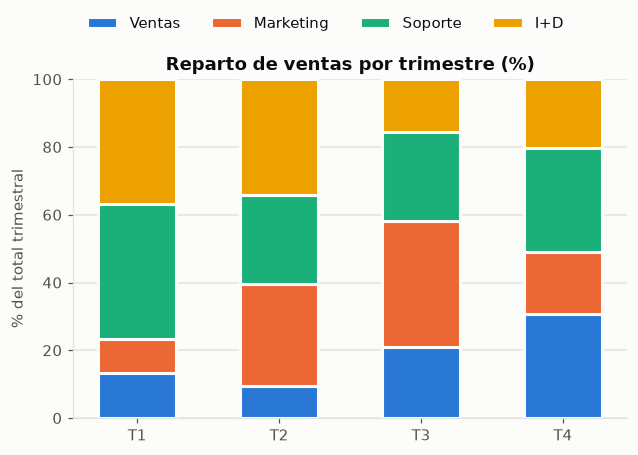

In [ ]:
x = np.arange(4)
bottom = np.zeros(4)
fig, ax = plt.subplots(figsize=(6.5, 4))
for c, area in enumerate(AREAS):
    ax.bar(x, pct[:, c], bottom=bottom, width=0.55, color=PAL[c],
           edgecolor=SURFACE, linewidth=2, label=area)   # 2 px de separación entre segmentos
    bottom += pct[:, c]
ax.set_xticks(x, TRIM)
ax.set_ylim(0, 100)
ax.set_ylabel("% del total trimestral")
ax.grid(False)
ax.grid(True, axis="y")
ax.legend(ncols=4, loc="lower left", bbox_to_anchor=(0, 1.1))
ax.set_title("Reparto de ventas por trimestre (%)", loc="center")
plt.show()

**Stacked Column Chart** — pocos periodos; cada columna muestra el total y sus partes en valor absoluto.

- **Cuándo usarlo:** cuando interesan a la vez el total de cada periodo y cómo se reparte.
- **Cómo leerlo:** la altura total es el total del periodo; cada segmento es la aportación de un área. Es fácil leer el segmento de la base, pero los de arriba son difíciles de comparar.
- **Evitar:** comparar segmentos que no están en la base; para eso, usa barras separadas.

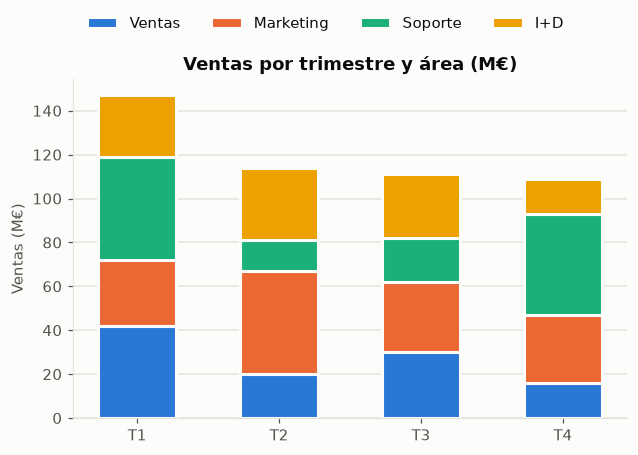

In [ ]:
x = np.arange(4)
bottom = np.zeros(4)
fig, ax = plt.subplots(figsize=(6.5, 4))
for c, area in enumerate(AREAS):
    ax.bar(x, datos[:, c], bottom=bottom, width=0.55, color=PAL[c],
           edgecolor=SURFACE, linewidth=2, label=area)
    bottom += datos[:, c]
ax.set_xticks(x, TRIM)
ax.set_ylabel("Ventas (M€)")
ygrid(ax)
ax.legend(ncols=4, loc="lower left", bbox_to_anchor=(0, 1.1))
ax.set_title("Ventas por trimestre y área (M€)", loc="center")
plt.show()

### Cambio en el tiempo, muchos periodos

Las dos áreas apiladas siguientes usan 36 meses.

In [ ]:
meses36 = np.arange(36)
serie = np.array([30 + 0.3 * meses36 + 5 * np.sin(meses36 / 4 + c) for c in range(4)])
serie_pct = serie / serie.sum(axis=0) * 100

**Stacked 100% Area Chart** — muchos periodos; el área completa suma el 100 % y muestra el reparto relativo en el tiempo.

- **Cuándo usarlo:** para ver cómo cambia la participación de cada parte en una serie larga.
- **Cómo leerlo:** el grosor de cada banda es su porcentaje en ese momento; si una banda se ensancha, gana peso frente a las demás.
- **Evitar:** leer valores absolutos; el gráfico no indica si el total crece o decrece.

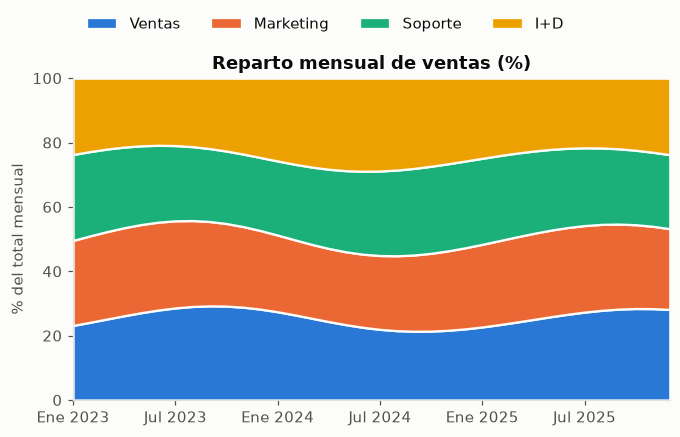

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.stackplot(meses36, serie_pct, colors=PAL[:4], labels=AREAS, edgecolor=SURFACE, linewidth=1.5)
ax.set_xlim(0, 35)
ax.set_ylim(0, 100)
ax.set_xticks(meses36[::6], [fmt_mes(m) for m in meses36[::6]])
ax.set_ylabel("% del total mensual")
ax.legend(ncols=4, loc="lower left", bbox_to_anchor=(0, 1.1))
ax.set_title("Reparto mensual de ventas (%)", loc="center")
plt.show()

**Stacked Area Chart** — muchos periodos; el área total es la suma de las partes en valor absoluto.

- **Cuándo usarlo:** para ver a la vez el total a lo largo del tiempo y la contribución de cada parte.
- **Cómo leerlo:** la altura total de la pila es el total del periodo; el grosor de cada banda es la aportación de esa parte.
- **Evitar:** comparar bandas que no están en la base; sus límites se mueven y son difíciles de juzgar.

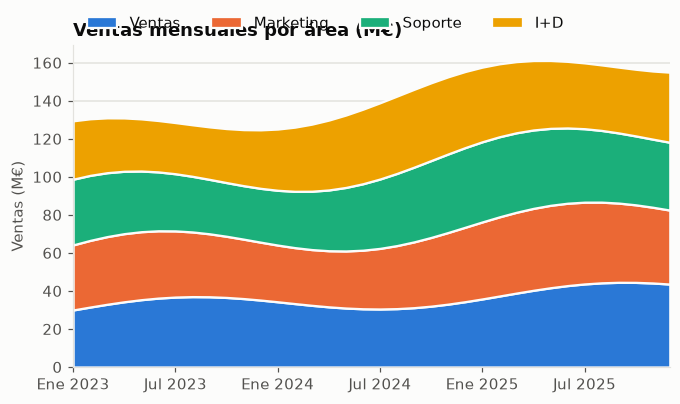

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.stackplot(meses36, serie, colors=PAL[:4], labels=AREAS, edgecolor=SURFACE, linewidth=1.5)
ax.set_xlim(0, 35)
ax.set_xticks(meses36[::6], [fmt_mes(m) for m in meses36[::6]])
ax.set_ylabel("Ventas (M€)")
ygrid(ax)
ax.legend(ncols=4, loc="lower left", bbox_to_anchor=(0, 1.0))
ax.set_title("Ventas mensuales por área (M€)")
plt.show()

### Estática

**Pie Chart** — reparte un todo en pocas partes; cada porción es una fracción del 100 %.

- **Cuándo usarlo:** solo para pocas partes (máximo cinco o seis) con diferencias claras, y cuando el mensaje es «esta parte es la mitad» o similar.
- **Cómo leerlo:** el ángulo de cada porción es proporcional a su valor; las etiquetas dan los números exactos.
- **Evitar:** partes con valores parecidos, porque el ojo no distingue bien los ángulos; en ese caso, barras ordenadas.

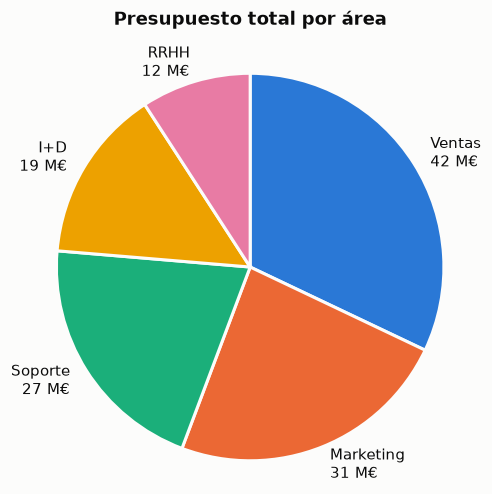

In [ ]:
partes = ["Ventas", "Marketing", "Soporte", "I+D", "RRHH"]
valores = [42, 31, 27, 19, 12]

fig, ax = plt.subplots(figsize=(5, 5))
ax.pie(valores, labels=[f"{p}\n{v} M€" for p, v in zip(partes, valores)], colors=PAL[:5],
       startangle=90, counterclock=False, wedgeprops={"edgecolor": SURFACE, "linewidth": 2},
       textprops={"color": TEXT})
ax.axis("equal")
ax.grid(False)
ax.set_title("Presupuesto total por área", pad=20, loc="center")
plt.show()

**Waterfall Chart** — muestra cómo se pasa de un total inicial a un total final mediante aportes (sumas) y restas.

- **Cuándo usarlo:** para explicar una variación, por ejemplo de ingresos a beneficio, mostrando qué suma y qué resta.
- **Cómo leerlo:** cada barra flotante empieza donde terminó la anterior; azul = aumento, naranja = descenso, gris = totales.
- **Evitar:** demasiados pasos (más de seis o siete), porque el gráfico pierde claridad.

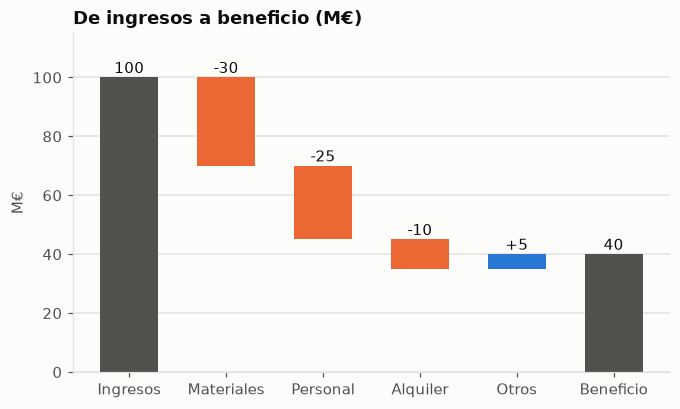

In [ ]:
etiquetas = ["Ingresos", "Materiales", "Personal", "Alquiler", "Otros", "Beneficio"]
deltas = [None, -30, -25, -10, +5, None]    # None = total

fig, ax = plt.subplots(figsize=(7, 4))
nivel = 100
for i, (et, d) in enumerate(zip(etiquetas, deltas)):
    if d is None:
        base, alto, color, txt = 0, nivel, TEXT2, f"{nivel}"
    else:
        base = min(nivel, nivel + d)
        alto = abs(d)
        color = PAL[1] if d < 0 else PAL[0]
        txt = f"{d:+d}"
        nivel += d
    ax.bar(i, alto, bottom=base, width=0.6, color=color)
    ax.text(i, base + alto + 1.5, txt, ha="center", color=TEXT)
ax.set_xticks(range(len(etiquetas)), etiquetas)
ax.set_ylim(0, 115)
ax.set_ylabel("M€")
ygrid(ax)
ax.set_title("De ingresos a beneficio (M€)")
plt.show()

**Stacked 100% Column Chart with Subcomponents** — componentes de componentes: cada columna suma el 100 %, se divide en grupos y cada grupo, en subcomponentes.

- **Cuándo usarlo:** cuando hay una jerarquía de dos niveles (canal → subcanal) y quieres ver el reparto de ambos.
- **Cómo leerlo:** el color base identifica el grupo (azul = digital, naranja = tienda); los tonos claros y oscuros de ese color son sus subcomponentes.
- **Evitar:** más de dos o tres grupos con varios subcomponentes cada uno; la leyenda se llena y cuesta seguir los segmentos.

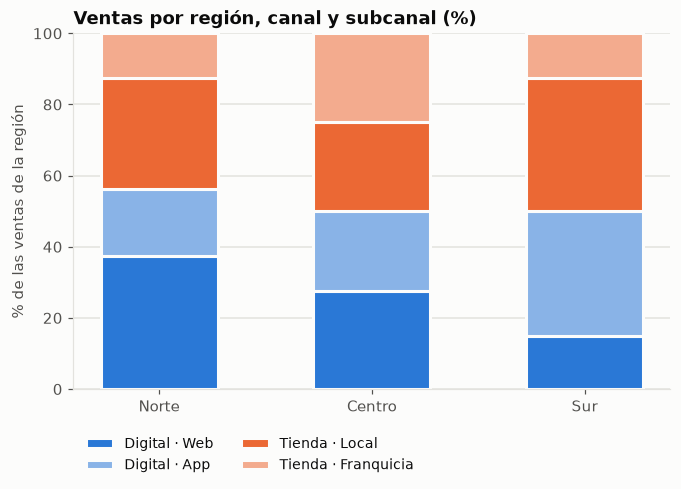

In [ ]:
regiones = ["Norte", "Centro", "Sur"]
subs = ["Web", "App", "Local", "Franquicia"]
grupo_de = ["Digital", "Digital", "Tienda", "Tienda"]
v = np.array([[30, 15, 25, 10],
              [22, 18, 20, 20],
              [12, 28, 30, 10]], dtype=float)
pct_sub = v / v.sum(axis=1, keepdims=True) * 100

def mezcla(color, t):
    # Aclara un color hacia la superficie (tono más claro del mismo grupo)
    c = np.array(to_rgb(color))
    s = np.array(to_rgb(SURFACE))
    return tuple(c * (1 - t) + s * t)

tonos = {"Digital": [PAL[0], mezcla(PAL[0], 0.45)],
         "Tienda": [PAL[1], mezcla(PAL[1], 0.45)]}
colores = []
contador = {"Digital": 0, "Tienda": 0}
for g in grupo_de:
    colores.append(tonos[g][contador[g]])
    contador[g] += 1

x = np.arange(len(regiones))
bottom = np.zeros(len(regiones))
fig, ax = plt.subplots(figsize=(7, 4.2))
for j, sub in enumerate(subs):
    ax.bar(x, pct_sub[:, j], bottom=bottom, width=0.55, color=colores[j],
           edgecolor=SURFACE, linewidth=2, label=f"{grupo_de[j]} · {sub}")
    bottom += pct_sub[:, j]
ax.set_xticks(x, regiones)
ax.set_ylim(0, 100)
ax.set_ylabel("% de las ventas de la región")
ax.grid(False)
ax.grid(True, axis="y")
ax.legend(ncols=2, loc="upper left", bbox_to_anchor=(0, -0.1), fontsize=9)
ax.set_title("Ventas por región, canal y subcanal (%)")
plt.show()

In [ ]:
pip install seaborn

  Using cached pandas-3.1.1-cp314-cp314-macosx_11_0_arm64.whl.metadata (16 kB)
Using cached pandas-3.1.1-cp314-cp314-macosx_11_0_arm64.whl (11.3 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [seaborn]━━━ 1/2 [seaborn]
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import seaborn as sns